# Task 4 — Random Forests & Ensembles: bagging, voting, stacking and AdaBoost on a spam filter

MOP 3231 · Machine Learning (Python) · Abror Imamsidikov

Data: UCI Spambase (Hopkins, Reeber, Forman & Suermondt, 1999; CC BY 4.0; doi:10.24432/C53G6X), deduplicated by the
instructor: 4204 e-mails, 57 numeric features, label `spam` (1 = spam, 0 = legitimate mail). Spam is the positive class;
a false positive is a legitimate mail flagged as spam.

## Part 0 — Setup

In [1]:
import sys

import matplotlib
import numpy
import pandas
import sklearn

print(sys.version.split()[0], numpy.__version__, pandas.__version__, sklearn.__version__, matplotlib.__version__)

3.12.12 2.3.4 2.3.3 1.7.2 3.10.7


In [2]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold, train_test_split

SEED = 2954          # last 4 digits of your student ID, as an integer (0421 -> 421)
data = pd.read_csv("data/spambase.csv")
feature_names = [c for c in data.columns if c != "spam"]
X, y = data[feature_names].to_numpy(), data["spam"].to_numpy()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=SEED)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
print(X.shape, round(100 * y.mean(), 1), X_train.shape, X_test.shape)

(4204, 57) 39.9 (3153, 57) (1051, 57)


**SEED = 2954** (the last four digits of my student ID). It seeds the train/test split, the folds `cv` and every
random model below. The check line prints `(4204, 57) 39.9 (3153, 57) (1051, 57)` as the handout requires.

### The fixed models (exactly as given in the handout)

In [3]:
import math

import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.ensemble import AdaBoostClassifier, BaggingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(random_state=SEED)
bag = BaggingClassifier(DecisionTreeClassifier(), n_estimators=100, oob_score=True, random_state=SEED)
rf = RandomForestClassifier(n_estimators=300, oob_score=True, random_state=SEED, n_jobs=-1)
lr = make_pipeline(FunctionTransformer(np.log1p), StandardScaler(), LogisticRegression(max_iter=2000))
bag_lr = BaggingClassifier(lr, n_estimators=50, random_state=SEED)
knn = make_pipeline(FunctionTransformer(np.log1p), StandardScaler(), KNeighborsClassifier(n_neighbors=15))
ada = AdaBoostClassifier(n_estimators=400, random_state=SEED)
members = [("lr", lr), ("knn", knn), ("tree", tree)]   # members of voting and stacking in Parts 3-4

In [4]:
from sklearn.model_selection import cross_validate

n_train, n_test = len(y_train), len(y_test)


def cv_scores(model):
    """Accuracy on each of the five folds of cv on the training split."""
    return cross_validate(model, X_train, y_train, cv=cv, scoring="accuracy", n_jobs=-1)["test_score"]


def fold_table(scores):
    """Table: one row per model, the five fold scores, mean and std (ddof=0)."""
    t = pd.DataFrame(scores).T
    t.columns = [f"fold {i + 1}" for i in range(t.shape[1])]
    t["mean"] = t.iloc[:, :5].mean(axis=1)
    t["std"] = t.iloc[:, :5].std(axis=1, ddof=0)
    return t


def paired(a, b):
    """Paired differences a - b (per fold or per draw) with mean, std and the 'inside the spread' verdict."""
    d = np.asarray(a) - np.asarray(b)
    row = {f"#{i + 1}": v for i, v in enumerate(d)}
    row["mean"], row["std"] = d.mean(), d.std()
    row["inside spread"] = bool(abs(d.mean()) <= d.std())
    return row

`cv_scores` is the handout's `cross_validate(model, X_train, y_train, cv=cv, scoring="accuracy")["test_score"]`
(with `n_jobs=-1` only for speed; it clones the model and uses the same folds). `paired` returns the paired
differences, their mean and std (`np.std`, ddof=0), and whether the difference is **inside the fold spread**
(|mean| ≤ std), in which case no winner may be named.

## Part 1 — Bagging and out-of-bag estimates

In [5]:
def oob_mask(sample_indices, n_samples):
    """Boolean mask of the rows that do NOT occur in sample_indices.

    sample_indices: list or 1-D integer array of row numbers in [0, n_samples - 1], repeats allowed, may be empty.
    Returns a new bool array of shape (n_samples,); element i is True exactly when i is not in sample_indices.
    """
    idx = np.asarray(sample_indices, dtype=np.int64).reshape(-1)   # a new array; the argument is not touched
    mask = np.ones(int(n_samples), dtype=bool)
    mask[idx] = False
    return mask

In [6]:
# the examples of the handout are part of the rules
assert oob_mask([0, 2, 2], 5).tolist() == [False, True, False, True, True]
assert oob_mask([], 3).tolist() == [True, True, True]
assert oob_mask(np.array([3, 0]), 4).tolist() == [False, True, True, False]
_a = np.array([3, 0]); oob_mask(_a, 4); assert _a.tolist() == [3, 0]          # argument unchanged
assert oob_mask([1], 2).dtype == bool and oob_mask([1], 2).shape == (2,)
print("oob_mask: all examples pass")

oob_mask: all examples pass


### 1.1 Out-of-bag share

In [7]:
bag.fit(X_train, y_train)
n = n_train
oob_share = np.array([oob_mask(s, n).mean() for s in bag.estimators_samples_])
print(f"n = {n} training rows, {len(bag.estimators_)} trees")
print(f"mean out-of-bag share per tree : {oob_share.mean():.4f}   formula (1 - 1/n)^n     = {(1 - 1 / n) ** n:.4f}")
print(f"mean in-bag share per tree     : {1 - oob_share.mean():.4f}   formula 1 - (1 - 1/n)^n = {1 - (1 - 1 / n) ** n:.4f}")
print(f"(range over the 100 trees: {oob_share.min():.4f} to {oob_share.max():.4f})")

n = 3153 training rows, 100 trees
mean out-of-bag share per tree : 0.3685   formula (1 - 1/n)^n     = 0.3678
mean in-bag share per tree     : 0.6315   formula 1 - (1 - 1/n)^n = 0.6322
(range over the 100 trees: 0.3543 to 0.3825)


### 1.2 Out-of-bag accuracy by hand

In [8]:
votes = np.zeros((n, 2))
for est, sample in zip(bag.estimators_, bag.estimators_samples_):
    m = oob_mask(sample, n)
    pred = est.predict(X_train[m]).astype(int)
    np.add.at(votes, (np.flatnonzero(m), pred), 1)       # one vote per tree for which the row is out of bag
oob_pred = np.argmax(votes, axis=1)                         # tie -> class 0
my_oob_acc = np.mean(oob_pred == y_train)
print(f"rows with no out-of-bag vote: {(votes.sum(axis=1) == 0).sum()}")
print(f"my out-of-bag accuracy = {my_oob_acc:.6f}")
print(f"bag.oob_score_         = {bag.oob_score_:.6f}")
print("equal:", my_oob_acc == bag.oob_score_)

rows with no out-of-bag vote: 0
my out-of-bag accuracy = 0.941326
bag.oob_score_         = 0.941326
equal: True


### 1.3 Five models on the same folds

In [9]:
scores = {name: cv_scores(m) for name, m in
          [("tree", tree), ("bag", bag), ("rf", rf), ("lr", lr), ("bag_lr", bag_lr)]}
fold_table(scores).round(4)

,fold 1,fold 2,fold 3,fold 4,fold 5,mean,std
tree,0.9017,0.8970,0.9255,0.8968,0.8968,0.9036,0.0111
bag,0.9255,0.9303,0.9556,0.9333,0.9333,0.9356,0.0104
rf,0.9477,0.9366,0.9635,0.9429,0.9349,0.9451,0.0103
lr,0.9113,0.9255,0.9540,0.9286,0.9444,0.9328,0.0150
bag_lr,0.9113,0.9271,0.9525,0.9317,0.9476,0.9340,0.0148


In [10]:
pd.DataFrame({"bag - tree": paired(scores["bag"], scores["tree"]),
              "rf - tree": paired(scores["rf"], scores["tree"]),
              "bag_lr - lr": paired(scores["bag_lr"], scores["lr"])}).T.round(4)

,#1,#2,#3,#4,#5,mean,std,inside spread
bag - tree,0.023772,0.033281,0.030111,0.036508,0.036508,0.032036,0.004765,False
rf - tree,0.045959,0.03962,0.038035,0.046032,0.038095,0.041548,0.003675,False
bag_lr - lr,0.0,0.001585,-0.001585,0.003175,0.003175,0.00127,0.00185,True


### 1.4 One forest, three estimates

In [11]:
rf.fit(X_train, y_train)            # fitted once and kept for Part 2
p_rf = rf.score(X_test, y_test)
se_rf = math.sqrt(p_rf * (1 - p_rf) / n_test)
rf_cv_mean, rf_cv_std = scores["rf"].mean(), scores["rf"].std()
print(f"oob_score_          : {rf.oob_score_:.4f}")
print(f"CV mean (5 folds)   : {rf_cv_mean:.4f}  (fold std {rf_cv_std:.4f})")
print(f"test accuracy p     : {p_rf:.4f}  ± SE {se_rf:.4f}   (n_test = {n_test})")
print(f"|oob - CV mean| = {abs(rf.oob_score_ - rf_cv_mean):.4f}  <= fold std {rf_cv_std:.4f}: "
      f"{abs(rf.oob_score_ - rf_cv_mean) <= rf_cv_std}")

oob_score_          : 0.9477
CV mean (5 folds)   : 0.9451  (fold std 0.0103)
test accuracy p     : 0.9458  ± SE 0.0070   (n_test = 1051)
|oob - CV mean| = 0.0025  <= fold std 0.0103: True


### Part 1 — answers

**Out-of-bag share.** The mean out-of-bag share per tree is 0.3685, against the formula (1 − 1/n)^n = 0.3678 for
n = 3153; the in-bag share is 0.6315 against 1 − (1 − 1/n)^n = 0.6322. They differ in the fourth decimal: about 37 %
of the training rows are left out of each bootstrap sample, as the formula says (it is close to 1/e ≈ 0.368).
My hand-made out-of-bag accuracy is 0.941326, exactly equal to `bag.oob_score_`.

**(a) Did bagging help?**
*Tree.* Bagging raised the CV accuracy from 0.9036 to 0.9356. The paired differences bag − tree are positive on all
five folds (0.024 to 0.037), mean +0.0320 with std 0.0048, so the gain is far outside the fold spread: bagging helps
the tree. The forest helps even more (rf − tree: mean +0.0415, std 0.0037, positive on every fold).
*Logistic regression.* bag_lr − lr has mean +0.0013 with std 0.0019 (fold differences between −0.0016 and +0.0032).
The mean is inside the fold spread, so my data cannot separate bagged and plain logistic regression.
*Mechanism.* Bagging averages models fitted on bootstrap samples, and an average of models only removes the
**variance** part of the error. A fully grown tree has high variance: a few changed rows change its splits and its
leaves, so 100 bootstrap trees make different mistakes and the majority vote cancels many of them. The random forest
also samples the features at each split, so its trees are less correlated and the average removes more variance.
Logistic regression is a stable, low-variance model (a smooth linear boundary): bootstrap fits give nearly the same
coefficients, so averaging 50 of them gives almost the same classifier and nothing is gained (its error is mostly bias).

**(b) Out-of-bag vs CV for the forest.** `oob_score_` = 0.9477 and the CV mean = 0.9451; the absolute difference
0.0025 is smaller than the std of the forest's five fold scores (0.0103), so the two are **in agreement** and the
out-of-bag score is a fair stand-in for the CV score here, at no extra cost (one fit instead of five). The test
accuracy is 0.9458 with standard error 0.0070; both the OOB score (0.0019 above it) and the CV mean (0.0006 below it)
lie well inside one standard error of the test accuracy, so all three estimates tell the same story.

## Part 2 — Evaluating the filter: curves, a threshold, importances

### 2.1 ROC and precision-recall curves on the test split

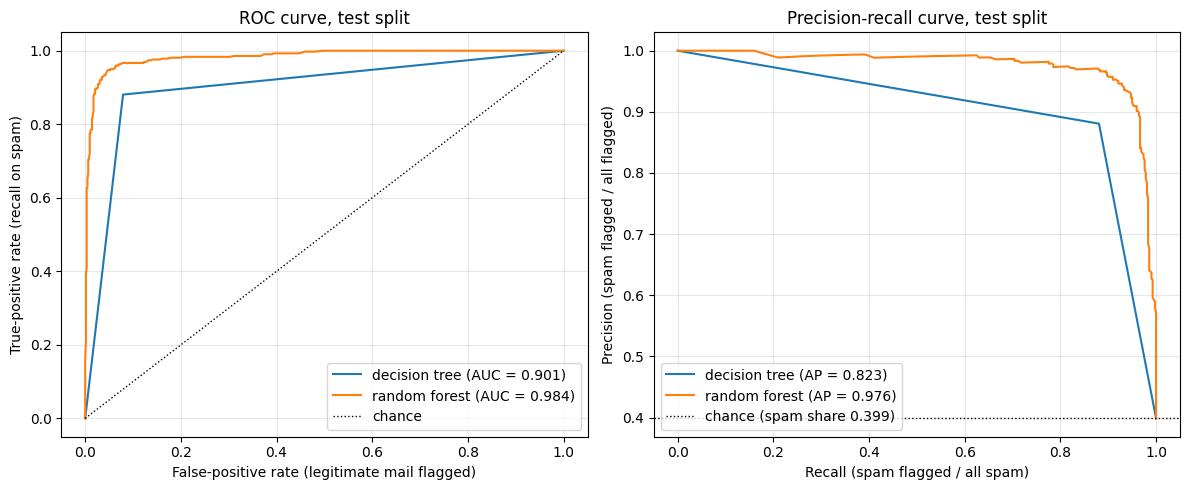

decision tree  ROC AUC = 0.9008   average precision = 0.8232
random forest  ROC AUC = 0.9836   average precision = 0.9760


In [12]:
from sklearn.metrics import (average_precision_score, confusion_matrix, precision_recall_curve, roc_auc_score,
                             roc_curve)

tree_fit = clone(tree).fit(X_train, y_train)
test_scores = {"decision tree": tree_fit.predict_proba(X_test)[:, 1],
               "random forest": rf.predict_proba(X_test)[:, 1]}

fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(12, 5))
for name, s in test_scores.items():
    fpr_c, tpr_c, _ = roc_curve(y_test, s)
    prec_c, rec_c, _ = precision_recall_curve(y_test, s)
    ax_roc.plot(fpr_c, tpr_c, label=f"{name} (AUC = {roc_auc_score(y_test, s):.3f})")
    ax_pr.plot(rec_c, prec_c, label=f"{name} (AP = {average_precision_score(y_test, s):.3f})")
ax_roc.plot([0, 1], [0, 1], "k:", lw=1, label="chance")
ax_roc.set(xlabel="False-positive rate (legitimate mail flagged)", ylabel="True-positive rate (recall on spam)",
           title="ROC curve, test split")
ax_pr.axhline(y_test.mean(), color="k", ls=":", lw=1, label=f"chance (spam share {y_test.mean():.3f})")
ax_pr.set(xlabel="Recall (spam flagged / all spam)", ylabel="Precision (spam flagged / all flagged)",
          title="Precision-recall curve, test split")
for ax in (ax_roc, ax_pr):
    ax.legend(loc="lower right" if ax is ax_roc else "lower left")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
for name, s in test_scores.items():
    print(f"{name:14s} ROC AUC = {roc_auc_score(y_test, s):.4f}   average precision = {average_precision_score(y_test, s):.4f}")

### 2.2 A threshold from the training split (out-of-fold probabilities)

In [13]:
from sklearn.model_selection import cross_val_predict

oof = cross_val_predict(rf, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
fpr_o, tpr_o, thr_o = roc_curve(y_train, oof, drop_intermediate=False)
ok = fpr_o <= 0.01                                     # out-of-fold FPR at most 1 %
best_recall = tpr_o[ok].max()
t = thr_o[ok & (tpr_o == best_recall)].max()           # largest threshold reaching that recall
i_t = np.flatnonzero(thr_o == t)[0]
print(f"t = {t!r}")
print(f"out-of-fold FPR at t    = {fpr_o[i_t]:.4f}  ({round(fpr_o[i_t] * (y_train == 0).sum())} of {(y_train == 0).sum()} legitimate)")
print(f"out-of-fold recall at t = {tpr_o[i_t]:.4f}")
# check directly with the rule "flagged when score >= t"
assert np.isclose(np.mean(oof[y_train == 0] >= t), fpr_o[i_t]) and np.isclose(np.mean(oof[y_train == 1] >= t), tpr_o[i_t])

t = np.float64(0.6766666666666666)
out-of-fold FPR at t    = 0.0090  (17 of 1896 legitimate)
out-of-fold recall at t = 0.8465


### 2.3 Apply it once to the test split

In [14]:
flag = (rf.predict_proba(X_test)[:, 1] >= t).astype(int)
cm = confusion_matrix(y_test, flag, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()
display(pd.DataFrame(cm, index=["true: legitimate (0)", "true: spam (1)"],
                     columns=["flagged: legitimate (0)", "flagged: spam (1)"]))
prec_t, rec_t, fpr_t = tp / (tp + fp), tp / (tp + fn), fp / (fp + tn)
print(f"precision = {prec_t:.4f}   recall = {rec_t:.4f}   FPR = {fpr_t:.4f}")
print(f"{fp} of the {fp + tn} legitimate test mails were flagged as spam.")
print(f"SE of the test FPR = {math.sqrt(fpr_t * (1 - fpr_t) / (fp + tn)):.4f}")

,flagged: legitimate (0),flagged: spam (1)
true: legitimate (0),621,11
true: spam (1),56,363


precision = 0.9706   recall = 0.8663   FPR = 0.0174
11 of the 632 legitimate test mails were flagged as spam.
SE of the test FPR = 0.0052


### 2.4 Permutation and impurity importances

In [15]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(rf, X_test, y_test, n_repeats=10, random_state=SEED, scoring="accuracy")
imp = pd.DataFrame({"permutation (test)": perm.importances_mean,
                    "permutation std": perm.importances_std,
                    "impurity (train)": rf.feature_importances_}, index=feature_names)
imp["rank permutation"] = imp["permutation (test)"].rank(ascending=False, method="min").astype(int)
imp["rank impurity"] = imp["impurity (train)"].rank(ascending=False, method="min").astype(int)
print("Top five by permutation importance:")
display(imp.sort_values("permutation (test)", ascending=False).head(5).round(4))
print("Top five by impurity importance:")
display(imp.sort_values("impurity (train)", ascending=False).head(5).round(4))

Top five by permutation importance:


,permutation (test),permutation std,impurity (train),rank permutation,rank impurity
word_freq_remove,0.0298,0.0028,0.0925,1,3
word_freq_hp,0.0135,0.0030,0.0453,2,9
char_freq_exclam,0.0119,0.0025,0.1025,3,1
char_freq_dollar,0.0094,0.0031,0.0949,4,2
word_freq_free,0.0063,0.0021,0.0630,5,6


Top five by impurity importance:


,permutation (test),permutation std,impurity (train),rank permutation,rank impurity
char_freq_exclam,0.0119,0.0025,0.1025,3,1
char_freq_dollar,0.0094,0.0031,0.0949,4,2
word_freq_remove,0.0298,0.0028,0.0925,1,3
capital_run_length_average,0.0030,0.0024,0.0643,7,4
word_freq_your,-0.0018,0.0017,0.0633,56,5


In [16]:
cols = ["word_freq_your", "capital_run_length_total", "word_freq_hp"]
display(imp.loc[cols].round(4))
corr = data[feature_names].corr().abs()
for c in cols[:2]:
    top = corr[c].drop(c).sort_values(ascending=False).head(3)
    print(c, "is most correlated with:", ", ".join(f"{k} ({v:.2f})" for k, v in top.items()))

,permutation (test),permutation std,impurity (train),rank permutation,rank impurity
word_freq_your,-0.0018,0.0017,0.0633,56,5
capital_run_length_total,-0.0020,0.0017,0.0456,57,8
word_freq_hp,0.0135,0.0030,0.0453,2,9


word_freq_your is most correlated with: word_freq_you (0.30), word_freq_business (0.23), word_freq_receive (0.19)
capital_run_length_total is most correlated with: capital_run_length_longest (0.46), word_freq_order (0.23), char_freq_dollar (0.21)


### Part 2 — answers

**Curves.** On the test split the forest dominates the tree: ROC AUC 0.984 against 0.901 and average precision 0.976
against 0.823. The single tree's curves are almost straight lines because it gives nearly every mail a probability of
0 or 1 (its leaves are pure), so it has essentially one operating point; the forest's averaged votes give a fine-grained
score that can be thresholded.

**Threshold.** On the out-of-fold forest probabilities of the training split, the threshold with the highest recall
among those with FPR ≤ 0.01 is t = 0.6767 (unrounded value printed above). There the out-of-fold FPR is 0.0090
(17 of 1896 legitimate training mails) and the recall is 0.8465.

**Applied once to the test split.** Precision 0.971, recall 0.866, FPR 0.0174: **11 of the 632 legitimate test mails
were flagged as spam.** The 1 % target **did not hold** on the test split: 1.74 % is above 1 % (1 % of 632 would be
at most 6 mails). The threshold was set to sit just below 1 % on the training folds, so it has no margin, and the
test FPR is estimated from only 632 legitimate mails (its standard error is about 0.005), so a test FPR above 1 %
for a threshold set right at the limit is not surprising. Recall (0.866 vs 0.846) carried over well. As the handout
says I do not change t after seeing these numbers; to meet the target more reliably one would choose t on the
training folds for a stricter target (for example 0.5 %), never on the test split.

**Importances.** The two lists share three features (`char_freq_exclam`, `char_freq_dollar`, `word_freq_remove`)
but rank them differently, and two features differ. A clear difference is **`word_freq_your`**: 5th by impurity
importance (0.063) but 56th of 57 by permutation importance (−0.0018, i.e. shuffling it does not hurt test
accuracy at all). The reason is how each is computed. The impurity importance adds up, over all splits in all 300
trees, the drop in Gini impurity on the **training** rows that each feature's splits produce. Because every split
considers only a random subset of features, a common, continuous word like "your" is often the best available
feature and gets used in many splits, collecting credit for every training-set impurity drop even when the same
information is also carried by other features (it is correlated with `word_freq_you` 0.30, `word_freq_business` 0.23,
`word_freq_receive` 0.19, and it overlaps with the stronger spam words). Impurity importance also favours continuous
features with many possible split points, and part of the credit comes from deep splits that only fit training rows. The permutation
importance instead shuffles one column on the **test** split and measures the loss of accuracy of the finished
forest. If other features carry the same signal, the many other trees and splits still classify the mail correctly,
so the drop is near zero. In the other direction, `word_freq_hp` (the "hp" of the donor's employer, a strong sign of
*legitimate* mail) is 2nd by permutation but only 9th by impurity: it is zero for most mails and so takes part in fewer
splits, but the forest relies on it for the mails where it is non-zero and has no substitute for it.

## Part 3 — Voting

In [17]:
def hard_vote(predictions, weights=None):
    """Weighted majority vote of several models' predicted labels, one label per sample.

    predictions: 2-D array-like (n_models, n_samples) of non-negative integer labels; row m = model m.
    weights: None (each model counts 1) or n_models non-negative numbers (not normalised).
    The count of a label is the sum of the weights of the models predicting it, added in model order;
    the label with the largest count wins, ties go to the smallest label (all counts 0 -> label 0).
    Returns a NumPy integer array of shape (n_samples,).
    """
    P = np.array(predictions, dtype=np.int64)          # a copy, the argument is not touched
    if P.ndim != 2:
        P = P.reshape(len(P), -1) if P.size else P.reshape(0, 0)
    n_models, n_samples = P.shape
    w = np.ones(n_models) if weights is None else np.array(weights, dtype=float).reshape(-1)
    if n_models == 0 or n_samples == 0:
        return np.zeros(n_samples, dtype=np.int64)
    counts = np.zeros((int(P.max()) + 1, n_samples))   # one row per label 0..max label
    cols = np.arange(n_samples)
    for m in range(n_models):                          # model 0 first
        counts[P[m], cols] += w[m]
    return np.argmax(counts, axis=0).astype(np.int64)  # argmax takes the first (smallest) label on a tie

In [18]:
assert hard_vote([[0, 1, 1], [0, 1, 0], [1, 1, 0]]).tolist() == [0, 1, 0]
assert hard_vote([[0, 1], [1, 0]]).tolist() == [0, 0]
assert hard_vote([[0, 1], [1, 0]], weights=[1, 2]).tolist() == [1, 0]
assert hard_vote([[2, 0], [2, 1], [0, 1]]).tolist() == [2, 1]
assert hard_vote([[0, 1], [1, 0]], weights=[0, 0]).tolist() == [0, 0]               # all counts 0 -> 0
assert hard_vote(np.array([[3, 3], [1, 2]]), weights=[1, 1]).tolist() == [1, 2]     # tie -> smallest label
_p, _w = [[0, 1], [1, 0]], [1, 2]; hard_vote(_p, _w); assert _p == [[0, 1], [1, 0]] and _w == [1, 2]
assert hard_vote([[0, 1]]).dtype.kind == "i"
print("hard_vote: all examples pass")

hard_vote: all examples pass


### 3.1 Reproduce scikit-learn

In [19]:
from sklearn.ensemble import VotingClassifier

fitted = {name: clone(m).fit(X_train, y_train) for name, m in members}
member_pred = np.vstack([fitted[name].predict(X_test) for name, _ in members])     # shape (3, n_test)
mine = hard_vote(member_pred)
sk_hard = VotingClassifier(members, voting="hard").fit(X_train, y_train).predict(X_test)
print("shape of the prediction matrix:", member_pred.shape)
print(f"fraction of test rows where hard_vote and VotingClassifier(voting='hard') agree: {np.mean(mine == sk_hard):.4f}")

shape of the prediction matrix: (3, 1051)
fraction of test rows where hard_vote and VotingClassifier(voting='hard') agree: 1.0000


### 3.2 Disagreement between the members

In [20]:
from itertools import combinations

names = [name for name, _ in members]
pd.DataFrame({"pair": [f"{names[a]} vs {names[b]}" for a, b in combinations(range(3), 2)],
              "fraction of test rows that differ": [np.mean(member_pred[a] != member_pred[b])
                                                    for a, b in combinations(range(3), 2)]}).set_index("pair").round(4)

,fraction of test rows that differ
pair,
lr vs knn,0.0390
lr vs tree,0.0837
knn vs tree,0.0847


### 3.3 Cross-validation

In [21]:
hard = VotingClassifier(members, voting="hard")
soft = VotingClassifier(members, voting="soft")
scores3 = {"lr": scores["lr"], "knn": cv_scores(knn), "tree": scores["tree"],
           "hard voting": cv_scores(hard), "soft voting": cv_scores(soft)}
best_member = max(["lr", "knn", "tree"], key=lambda k: scores3[k].mean())     # chosen on the training folds
print("best member (highest CV mean):", best_member)
fold_table(scores3).round(4)

best member (highest CV mean): lr


,fold 1,fold 2,fold 3,fold 4,fold 5,mean,std
lr,0.9113,0.9255,0.9540,0.9286,0.9444,0.9328,0.0150
knn,0.9033,0.9223,0.9271,0.9143,0.9444,0.9223,0.0137
tree,0.9017,0.8970,0.9255,0.8968,0.8968,0.9036,0.0111
hard voting,0.9223,0.9303,0.9572,0.9365,0.9476,0.9388,0.0124
soft voting,0.9303,0.9271,0.9604,0.9381,0.9381,0.9388,0.0116


In [22]:
pd.DataFrame({f"hard - {best_member}": paired(scores3["hard voting"], scores3[best_member]),
              f"soft - {best_member}": paired(scores3["soft voting"], scores3[best_member])}).T.round(4)

,#1,#2,#3,#4,#5,mean,std,inside spread
hard - lr,0.011094,0.004754,0.00317,0.007937,0.003175,0.006026,0.003074,False
soft - lr,0.019017,0.001585,0.006339,0.009524,-0.006349,0.006023,0.008414,True


### Part 3 — answers

`hard_vote` reproduces `VotingClassifier(members, voting="hard")` on all 1051 test rows (agreement 1.0000).
The members disagree on 3.9 % of the test rows (lr vs knn) and on about 8.4 % for each of them against the tree:
the tree makes different mistakes from the two smooth models, which is what voting needs.

On the same five folds the best member is logistic regression (CV mean 0.9328 ± 0.0150), ahead of knn (0.9223)
and the tree (0.9036). Both voting ensembles have CV mean 0.9388.

* **Hard voting vs lr:** paired differences +0.0111, +0.0048, +0.0032, +0.0079, +0.0032; mean +0.0060, std 0.0031.
  The mean is larger than the std, so the difference is **outside the fold spread**: hard voting beats the best
  member, by a small margin (about 0.6 points), and it is better on every one of the five folds.
* **Soft voting vs lr:** paired differences +0.0190, +0.0016, +0.0063, +0.0095, −0.0063; mean +0.0060, std 0.0084.
  The mean is **inside the fold spread** (0.0060 ≤ 0.0084): soft voting is worse than lr on one fold and much better on
  another, so I name **no winner** — my data cannot separate soft voting from logistic regression.

So the same mean gain is a win for hard voting and not for soft voting: what decides is how consistent the gain is
from fold to fold. A possible reason is that the tree always outputs probabilities of 0 or 1, so in the soft average it
is the most confident member even though it is the weakest, which can help on some folds and hurt on others (fold 5).

## Part 4 — Stacking

### 4.1 Out-of-fold stacking by hand, checked against `StackingClassifier`

In [23]:
from sklearn.ensemble import StackingClassifier

Z_oof = np.column_stack([cross_val_predict(m, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
                         for _, m in members])                                  # shape (n_train, 3)
meta_oof = LogisticRegression().fit(Z_oof, y_train)
Z_test = np.column_stack([fitted[name].predict_proba(X_test)[:, 1] for name, _ in members])   # members fitted on all of X_train
my_stack_pred = meta_oof.predict(Z_test)

stack = StackingClassifier(members, LogisticRegression(), cv=cv).fit(X_train, y_train)
print("Z_oof shape:", Z_oof.shape)
print("my coefficients     :", meta_oof.coef_.ravel().round(6), " intercept", meta_oof.intercept_.round(6))
print("sklearn coefficients:", stack.final_estimator_.coef_.ravel().round(6), " intercept", stack.final_estimator_.intercept_.round(6))
print(f"largest |difference| of the coefficient vectors: {np.abs(meta_oof.coef_ - stack.final_estimator_.coef_).max():.2e}")
print("test predictions identical:", bool(np.array_equal(my_stack_pred, stack.predict(X_test))))
print(f"test accuracy: by hand {np.mean(my_stack_pred == y_test):.4f}   StackingClassifier {stack.score(X_test, y_test):.4f}")

Z_oof shape: (3153, 3)
my coefficients     : [3.620498 2.968019 1.587295]  intercept [-3.963361]
sklearn coefficients: [3.620498 2.968019 1.587295]  intercept [-3.963361]
largest |difference| of the coefficient vectors: 0.00e+00
test predictions identical: True
test accuracy: by hand 0.9410   StackingClassifier 0.9410


### 4.2 Naive stacking (in-sample predictions)

In [24]:
Z_naive = np.column_stack([clone(m).fit(X_train, y_train).predict_proba(X_train)[:, 1] for _, m in members])
meta_naive = LogisticRegression().fit(Z_naive, y_train)
coef_table = pd.DataFrame({"naive (in-sample)": meta_naive.coef_.ravel(),
                           "out-of-fold": meta_oof.coef_.ravel()}, index=names)
coef_table.loc["intercept"] = [meta_naive.intercept_[0], meta_oof.intercept_[0]]
display(coef_table.round(3))
print("training accuracy of each member on its own training rows (in-sample) vs out-of-fold:")
display(pd.DataFrame({"in-sample": [np.mean((Z_naive[:, j] >= 0.5) == y_train) for j in range(3)],
                      "out-of-fold": [np.mean((Z_oof[:, j] >= 0.5) == y_train) for j in range(3)]},
                     index=names).round(4))

,naive (in-sample),out-of-fold
lr,1.951,3.620
knn,1.893,2.968
tree,8.286,1.587
intercept,-6.082,-3.963


training accuracy of each member on its own training rows (in-sample) vs out-of-fold:


,in-sample,out-of-fold
lr,0.9401,0.9328
knn,0.9337,0.9223
tree,1.0000,0.9036


### 4.3 Cross-validation

In [25]:
scores4 = {"stacking": cv_scores(StackingClassifier(members, LogisticRegression(), cv=cv)),
           "soft voting": scores3["soft voting"], best_member: scores3[best_member]}
display(fold_table(scores4).round(4))
pd.DataFrame({f"stack - {best_member}": paired(scores4["stacking"], scores3[best_member]),
              "stack - soft voting": paired(scores4["stacking"], scores3["soft voting"])}).T.round(4)

,fold 1,fold 2,fold 3,fold 4,fold 5,mean,std
stacking,0.9287,0.9287,0.9572,0.9413,0.9381,0.9388,0.0105
soft voting,0.9303,0.9271,0.9604,0.9381,0.9381,0.9388,0.0116
lr,0.9113,0.9255,0.9540,0.9286,0.9444,0.9328,0.0150


,#1,#2,#3,#4,#5,mean,std,inside spread
stack - lr,0.017433,0.00317,0.00317,0.012698,-0.006349,0.006024,0.008296,True
stack - soft voting,-0.001585,0.001585,-0.00317,0.003175,0.0,0.000001,0.002243,True


### Part 4 — answers

My out-of-fold stacking reproduces `StackingClassifier`: the meta-learner coefficients (lr 3.620, knn 2.968,
tree 1.587) agree to the last digit (largest absolute difference 0.0), the 1051 test predictions are identical, and
both test accuracies are 0.9410.

**(a) The tree's weight.** With naive (in-sample) predictions the meta-learner gives the tree the largest weight by
far, 8.29, against 1.95 for lr and 1.89 for knn. With out-of-fold predictions the tree has the **smallest** weight,
1.59, behind lr (3.62) and knn (2.97). The reason: a fully grown tree memorises its training rows, so its in-sample
probabilities are 0 or 1 and 100 % correct (training accuracy 1.0000 in the table above). Logistic regression and
15-NN cannot fit their own training rows perfectly, so in-sample the tree looks like a perfect predictor and the
meta-learner trusts it most. That trust is false: on rows it did not see the tree is the weakest member (out-of-fold
accuracy about 0.90). Out-of-fold predictions show each member as it behaves on new data, so the meta-learner learns
the real reliability and down-weights the tree. This is why `StackingClassifier` uses cross-validated predictions.

**(b) Stacking vs the best member and vs soft voting** (same five folds; stacking mean 0.9388 ± 0.0105):
* stack − lr: +0.0174, +0.0032, +0.0032, +0.0127, −0.0063; mean +0.0060, std 0.0083 → **inside the fold spread**.
* stack − soft voting: −0.0016, +0.0016, −0.0032, +0.0032, 0.0000; mean 0.0000, std 0.0022 → **inside the fold spread**.

So I declare **no winner** in either comparison: my data cannot separate stacking from logistic regression, nor
stacking from soft voting. Stacking costs five extra fits per member here and gives the same accuracy as simply
averaging the three probabilities.

## Part 5 — AdaBoost and label noise

In [26]:
def adaboost_step(y_true, y_pred, weights):
    """One AdaBoost round: return (alpha, new_weights) for a learner's predictions and the current row weights.

    eps = (weight of the wrong rows) / (total weight), alpha = ln((1 - eps) / eps); wrong rows are multiplied by
    exp(alpha), right rows are kept, and all weights are divided by their sum. eps = 0 -> (math.inf, weights / sum).
    eps >= 0.5 is not special-cased (alpha <= 0). The arguments are not modified; new_weights is a new float array.
    """
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    w = np.array(weights, dtype=float).reshape(-1)       # a copy
    wrong = y_pred != y_true
    eps = w[wrong].sum() / w.sum()
    if eps == 0:
        return math.inf, w / w.sum()
    alpha = math.log((1 - eps) / eps)
    w[wrong] = w[wrong] * math.exp(alpha)
    return float(alpha), w / w.sum()

In [27]:
def _check(call, alpha, new_w):
    a, w = adaboost_step(*call)
    assert (a == alpha) if math.isinf(alpha) else math.isclose(a, alpha, abs_tol=1e-12), (call, a)
    assert isinstance(a, float) and isinstance(w, np.ndarray) and w.dtype.kind == "f" and w.shape == (len(call[0]),)
    assert np.allclose(w, new_w), (call, w)

_check(([1, 1, 0, 0], [1, 0, 0, 0], [1, 1, 1, 1]), math.log(3), [1/6, 1/2, 1/6, 1/6])
_check(([1, 1, 1, 0], [0, 0, 0, 0], [1, 1, 1, 1]), -math.log(3), [1/6, 1/6, 1/6, 1/2])
_check(([1, 0], [0, 0], [1, 1]), 0.0, [0.5, 0.5])
_check(([1, 0, 1], [1, 0, 1], [2, 2, 4]), math.inf, [0.25, 0.25, 0.5])
_check(([-1, 1, 1, -1], [-1, 1, -1, -1], [0.1, 0.2, 0.1, 0.1]), math.log(4), [0.125, 0.25, 0.5, 0.125])
_w = np.array([2.0, 2.0, 4.0]); adaboost_step([1, 0, 1], [0, 0, 1], _w); assert _w.tolist() == [2.0, 2.0, 4.0]
print("adaboost_step: all examples pass")

adaboost_step: all examples pass


### 5.1 The lecture's three rounds (toy example: three stumps)

In [28]:
x       = np.arange(1, 11)
y_toy   = np.array([1, 1, 1, 0, 0, 0, 1, 1, 1, 0])
stump_1 = np.where(x <= 3.5, 1, 0)      # 1 if x <= 3.5, else 0
stump_2 = np.where(x <= 9.5, 1, 0)      # 1 if x <= 9.5, else 0
stump_3 = np.where(x <= 6.5, 0, 1)      # 0 if x <= 6.5, else 1

w_toy = np.full(10, 0.1)
rows = []
for r, stump in enumerate([stump_1, stump_2, stump_3], start=1):
    wrong = stump != y_toy
    eps = w_toy[wrong].sum() / w_toy.sum()
    alpha, w_toy = adaboost_step(y_toy, stump, w_toy)
    rows.append({"round": r, "wrong rows (x)": x[wrong].tolist(), "eps": round(eps, 3), "alpha": round(alpha, 3),
                 **{f"w(x={i})": round(v, 3) for i, v in zip(x, w_toy)}})
pd.DataFrame(rows).set_index("round")

,wrong rows (x),eps,alpha,w(x=1),w(x=2),w(x=3),w(x=4),w(x=5),w(x=6),w(x=7),w(x=8),w(x=9),w(x=10)
round,,,,,,,,,,,,,
1,"[7, 8, 9]",0.300,0.847,0.071,0.071,0.071,0.071,0.071,0.071,0.167,0.167,0.167,0.071
2,"[4, 5, 6]",0.214,1.299,0.045,0.045,0.045,0.167,0.167,0.167,0.106,0.106,0.106,0.045
3,"[1, 2, 3, 10]",0.182,1.504,0.125,0.125,0.125,0.102,0.102,0.102,0.065,0.065,0.065,0.125


### 5.2 Check scikit-learn's first five rounds

In [29]:
ada.fit(X_train, y_train)                     # fitted once and kept for 5.3
w = np.full(n_train, 1 / n_train)
check = []
for t_round in range(5):
    pred = ada.estimators_[t_round].predict(X_train)
    eps = w[pred != y_train].sum() / w.sum()
    alpha, w = adaboost_step(y_train, pred, w)
    check.append({"round": t_round + 1, "my eps": eps, "sklearn eps": ada.estimator_errors_[t_round],
                  "my alpha": alpha, "sklearn alpha": ada.estimator_weights_[t_round]})
check = pd.DataFrame(check).set_index("round")
display(check.round(6))
print(f"largest |alpha difference| over 5 rounds: {np.abs(check['my alpha'] - check['sklearn alpha']).max():.2e}")
print(f"largest |eps difference|   over 5 rounds: {np.abs(check['my eps'] - check['sklearn eps']).max():.2e}")

,my eps,sklearn eps,my alpha,sklearn alpha
round,,,,
1,0.212179,0.212179,1.311841,1.311841
2,0.249202,0.249202,1.102872,1.102872
3,0.287303,0.287303,0.908519,0.908519
4,0.280271,0.280271,0.943117,0.943117
5,0.334596,0.334596,0.687469,0.687469


largest |alpha difference| over 5 rounds: 3.33e-16
largest |eps difference|   over 5 rounds: 5.55e-17


### 5.3 Error by round, and the number of rounds chosen on the training folds

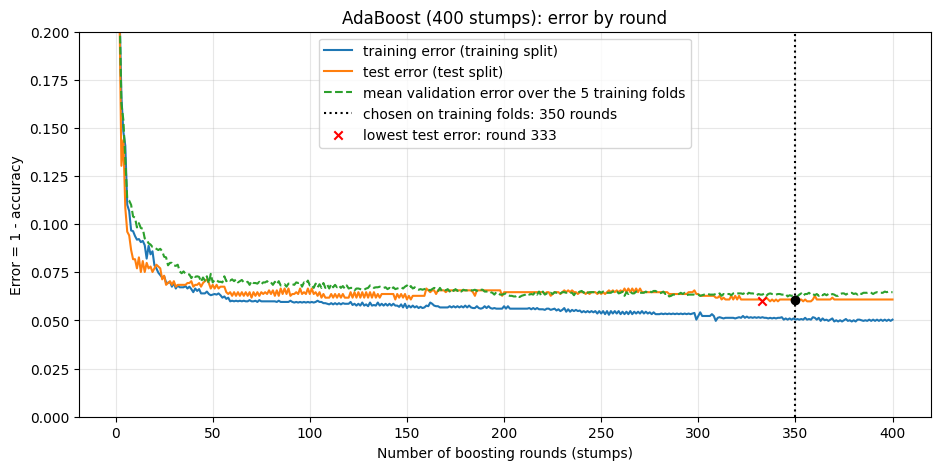

chosen number of rounds (training folds): 350  (mean validation accuracy 0.9378)
test error at the chosen round          : 0.0609
round with the lowest test error        : 333  (test error 0.0599)
difference 0.0010  vs SE of the test accuracy at the chosen round 0.0074  -> larger than SE: False
training error after 400 rounds: 0.0504   test error after 400 rounds: 0.0609


In [30]:
train_err = 1 - np.array(list(ada.staged_score(X_train, y_train)))
test_err = 1 - np.array(list(ada.staged_score(X_test, y_test)))

fold_curves = []
for tr_idx, va_idx in cv.split(X_train, y_train):                 # training split only
    m = clone(ada).fit(X_train[tr_idx], y_train[tr_idx])
    fold_curves.append(list(m.staged_score(X_train[va_idx], y_train[va_idx])))
fold_curves = np.array(fold_curves)
cv_curve = fold_curves.mean(axis=0)                               # mean validation accuracy after 1..400 rounds
chosen = int(np.argmax(cv_curve)) + 1                             # smallest round with the highest mean accuracy
best_test = int(np.argmin(test_err)) + 1                          # smallest round with the lowest test error
rounds = np.arange(1, len(test_err) + 1)

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(rounds, train_err, label="training error (training split)")
ax.plot(rounds, test_err, label="test error (test split)")
ax.plot(rounds, 1 - cv_curve, "--", label="mean validation error over the 5 training folds")
ax.axvline(chosen, color="k", ls=":", label=f"chosen on training folds: {chosen} rounds")
ax.scatter([chosen], [test_err[chosen - 1]], color="k", zorder=3)
ax.scatter([best_test], [test_err[best_test - 1]], color="red", marker="x", zorder=3,
           label=f"lowest test error: round {best_test}")
ax.set(xlabel="Number of boosting rounds (stumps)", ylabel="Error = 1 - accuracy",
       title="AdaBoost (400 stumps): error by round", ylim=(0, 0.2))
ax.legend()
ax.grid(alpha=0.3)
plt.show()

p_ch = 1 - test_err[chosen - 1]
se_ch = math.sqrt(p_ch * (1 - p_ch) / n_test)
print(f"chosen number of rounds (training folds): {chosen}  (mean validation accuracy {cv_curve[chosen - 1]:.4f})")
print(f"test error at the chosen round          : {test_err[chosen - 1]:.4f}")
print(f"round with the lowest test error        : {best_test}  (test error {test_err[best_test - 1]:.4f})")
print(f"difference {test_err[chosen - 1] - test_err[best_test - 1]:.4f}  vs SE of the test accuracy at the chosen round {se_ch:.4f}"
      f"  -> larger than SE: {abs(test_err[chosen - 1] - test_err[best_test - 1]) > se_ch}")
print(f"training error after 400 rounds: {train_err[-1]:.4f}   test error after 400 rounds: {test_err[-1]:.4f}")

### 5.4 Label noise: tree, forest and AdaBoost at 0 % and 20 % noise

In [31]:
def flip_labels(y, rate, seed):
    rng = np.random.default_rng(seed)
    idx = rng.choice(len(y), size=round(rate * len(y)), replace=False)
    y_noisy = y.copy()
    y_noisy[idx] = 1 - y_noisy[idx]
    return y_noisy, idx


ada200 = AdaBoostClassifier(n_estimators=200, random_state=SEED)
noise_models = {"tree": tree, "rf": rf, "ada200": ada200}
clean_acc = {k: clone(m).fit(X_train, y_train).score(X_test, y_test) for k, m in noise_models.items()}
noisy_acc = {k: [] for k in noise_models}
weight_share, n_stumps = [], []
for r in range(5):
    y_noisy, idx = flip_labels(y_train, 0.20, SEED + r)            # only training labels are flipped
    for k, m in noise_models.items():
        fitted_noisy = clone(m).fit(X_train, y_noisy)
        noisy_acc[k].append(fitted_noisy.score(X_test, y_test))   # scored on the clean test labels
        if k == "ada200":                                         # 5.5: replay the weights of all stumps
            w = np.full(n_train, 1 / n_train)
            for stump in fitted_noisy.estimators_:
                _, w = adaboost_step(y_noisy, stump.predict(X_train), w)
            weight_share.append(w[idx].sum())
            n_stumps.append(len(fitted_noisy.estimators_))

loss = {k: clean_acc[k] - np.array(noisy_acc[k]) for k in noise_models}
noise_table = pd.DataFrame({
    "test acc 0 %": {k: f"{clean_acc[k]:.4f}" for k in noise_models},
    "test acc 20 % (mean ± std)": {k: f"{np.mean(noisy_acc[k]):.4f} ± {np.std(noisy_acc[k]):.4f}" for k in noise_models},
    "loss (mean ± std)": {k: f"{loss[k].mean():.4f} ± {loss[k].std():.4f}" for k in noise_models},
    **{f"loss draw {r}": {k: f"{loss[k][r]:.4f}" for k in noise_models} for r in range(5)}})
noise_table

,test acc 0 %,test acc 20 % (mean ± std),loss (mean ± std),loss draw 0,loss draw 1,loss draw 2,loss draw 3,loss draw 4
tree,0.9049,0.7225 ± 0.0159,0.1823 ± 0.0159,0.1865,0.1855,0.1598,0.1722,0.2074
rf,0.9458,0.9043 ± 0.0028,0.0415 ± 0.0028,0.0419,0.0438,0.0362,0.0438,0.0419
ada200,0.9353,0.9208 ± 0.0022,0.0145 ± 0.0022,0.0162,0.0114,0.0152,0.0171,0.0124


In [32]:
print("Losses paired by draw (same flipped rows for all three models):")
pd.DataFrame({"loss tree - loss rf": paired(loss["tree"], loss["rf"]),
              "loss tree - loss ada200": paired(loss["tree"], loss["ada200"]),
              "loss rf - loss ada200": paired(loss["rf"], loss["ada200"])}).T.round(4)

Losses paired by draw (same flipped rows for all three models):


,#1,#2,#3,#4,#5,mean,std,inside spread
loss tree - loss rf,0.144624,0.14177,0.123692,0.128449,0.165557,0.140818,0.014654,False
loss tree - loss ada200,0.170314,0.17412,0.144624,0.15509,0.195052,0.16784,0.017249,False
loss rf - loss ada200,0.02569,0.03235,0.020932,0.026641,0.029496,0.027022,0.003834,False


### 5.5 Where AdaBoost's weight ends up

In [33]:
display(pd.DataFrame({"draw": range(5), "stumps": n_stumps, "share of weight on flipped rows (final w)": weight_share}
                     ).set_index("draw").round(4))
print(f"final share on the flipped rows: {np.mean(weight_share):.4f} ± {np.std(weight_share):.4f}")
print(f"share before the first round  : {len(idx) / n_train:.4f}  ({len(idx)} of {n_train} rows flipped)")

,stumps,share of weight on flipped rows (final w)
draw,,
0,200,0.3948
1,200,0.3895
2,200,0.4039
3,200,0.4019
4,200,0.4044


final share on the flipped rows: 0.3989 ± 0.0058
share before the first round  : 0.2001  (631 of 3153 rows flipped)


### Part 5 — answers

**Lecture example.** Round 1 gives ε = 0.3, α = 0.847, weight 0.071 on the seven right rows and 0.167 on the three wrong
rows (x = 7, 8, 9), exactly the values of the slide. Feeding these weights on, round 2 (wrong rows x = 4, 5, 6) gives
ε = 0.214, α = 1.299, and round 3 (wrong rows x = 1, 2, 3, 10) gives ε = 0.182, α = 1.504; in each round the weights of
the wrong rows rise to a total of 0.5, as AdaBoost's update always does.

**scikit-learn.** Replaying the first five stumps of `ada` with my function, the largest absolute difference from
`estimator_weights_` is 3.3e-16 and from `estimator_errors_` is 5.6e-17, i.e. floating-point rounding only: my update is
the one scikit-learn uses (SAMME with two classes, α = ln((1 − ε)/ε)).

**(a) Number of rounds.** The training error keeps falling slowly over the 400 rounds (0.212 after one stump, 0.057 after
200, 0.050 after 400), while the test error flattens after about 100 rounds (0.064 at 100) and then only wobbles. On the mean validation curve of the five training folds the best number of rounds is **350**
(mean validation accuracy 0.9378). The test error there is 0.0609; the test curve is lowest at round **333** with error
0.0599. The two differ by 0.0010, much less than the standard error of the test accuracy (0.0074), so the number chosen on
the training folds is as good as the best test round within what 1051 test mails can resolve — and it was found without
looking at the test split. The test curve is very flat in this region: between rounds 200 and 400 it stays between 0.060 and 0.067, a range
smaller than one standard error, so the exact number of rounds hardly matters here.

**(b) Label noise.** With 20 % of the training labels flipped:
* the **single tree loses the most**: 0.9049 → 0.7225, loss 0.182 ± 0.016;
* the forest loses 0.041 ± 0.003 (0.9458 → 0.9043);
* AdaBoost with 200 stumps loses the least, 0.014 ± 0.002 (0.9353 → 0.9208).

Paired by draw, every ordering is far outside the spread: tree − rf loss 0.141 ± 0.015, tree − ada200 0.168 ± 0.017,
rf − ada200 0.027 ± 0.004; in each of the five draws the order is the same (tree ≫ rf > ada200).

*Mechanism.* An unpruned tree grows until every leaf is pure, so it **memorises** each of the 631 wrong labels as its own
little region; at test time every mail that falls near a flipped training row inherits its wrong label, and the accuracy
drops by about 18 points (close to the 20 % of corrupted labels). The forest's trees memorise the noise too, but each tree
sees a different bootstrap sample and different features, so a flipped row only fools the trees that contain it and the
majority vote of 300 trees mostly overrules them: the loss falls to about 4 points. AdaBoost is often called sensitive
to label noise, and my weights show why: after 200 rounds the flipped rows hold 0.399 ± 0.006 of the total weight, twice
their share of 0.200 at the start — the booster keeps concentrating on rows it cannot fit. But its weak learners are
**stumps**: a single split on one feature cannot isolate individual mislabelled rows, and the final model is a weighted
sum of 200 one-split rules, a smooth, low-variance model. So the extra weight on the noisy rows only moves the thresholds
a little and the loss stays small. With deeper base trees or many more rounds the booster could start fitting the flipped
rows, and its loss would grow.

## Part 6 — Recommendation and reproducibility

In [34]:
all_scores = {"rf": scores["rf"], "bag": scores["bag"], "lr": scores["lr"], "hard voting": scores3["hard voting"],
              "soft voting": scores3["soft voting"], "stacking": scores4["stacking"], "tree": scores["tree"]}
display(fold_table(all_scores).sort_values("mean", ascending=False).round(4))
pd.DataFrame({f"rf - {k}": paired(all_scores["rf"], all_scores[k]) for k in all_scores if k != "rf"}).T.round(4)

,fold 1,fold 2,fold 3,fold 4,fold 5,mean,std
rf,0.9477,0.9366,0.9635,0.9429,0.9349,0.9451,0.0103
hard voting,0.9223,0.9303,0.9572,0.9365,0.9476,0.9388,0.0124
stacking,0.9287,0.9287,0.9572,0.9413,0.9381,0.9388,0.0105
soft voting,0.9303,0.9271,0.9604,0.9381,0.9381,0.9388,0.0116
bag,0.9255,0.9303,0.9556,0.9333,0.9333,0.9356,0.0104
lr,0.9113,0.9255,0.9540,0.9286,0.9444,0.9328,0.0150
tree,0.9017,0.8970,0.9255,0.8968,0.8968,0.9036,0.0111


,#1,#2,#3,#4,#5,mean,std,inside spread
rf - bag,0.022187,0.006339,0.007924,0.009524,0.001587,0.009512,0.006871,False
rf - lr,0.03645,0.011094,0.009509,0.014286,-0.009524,0.012363,0.014647,True
rf - hard voting,0.025357,0.006339,0.006339,0.006349,-0.012698,0.006337,0.012034,True
rf - soft voting,0.017433,0.009509,0.00317,0.004762,-0.003175,0.00634,0.006873,True
rf - stacking,0.019017,0.007924,0.006339,0.001587,-0.003175,0.006339,0.007434,True
rf - tree,0.045959,0.03962,0.038035,0.046032,0.038095,0.041548,0.003675,False


### Recommendation

I recommend the **random forest** with the threshold **t = 0.677** (flag a mail when its forest probability is ≥ t),
chosen on out-of-fold probabilities of the training split, where it gave FPR 0.009 and recall 0.846. It has the highest
CV accuracy (0.9451 ± 0.0103) and clearly beats the tree (+0.042) and the bagged trees (+0.010 ± 0.007), it gives a
smooth score with test ROC AUC 0.984, and its out-of-bag score (0.948) checks itself for free; it also lost only 0.041
accuracy at 20 % label noise against 0.182 for a single tree. Its lead over logistic regression (+0.012 ± 0.015), hard
voting (+0.006 ± 0.012), soft voting (+0.006 ± 0.007) and stacking (+0.006 ± 0.007) lies **inside the fold spread**, as
do the gains of soft voting and stacking over logistic regression, so these differences do not support choosing one
over the other. On the test split the threshold kept the precision at 0.971 and recall at 0.866 but flagged 11 of 632
legitimate mails (FPR 1.74 %), so the 1 % target was not met. Before deployment I would therefore set t again on the
out-of-fold probabilities of the training split with a safety margin (for example for an out-of-fold FPR of 0.5 %),
not on the test split, which has now been used once.

### Reproducibility

* The first cell prints the Python and library versions (pinned in `requirements.txt`: numpy 2.3.4, pandas 2.3.3,
  scikit-learn 1.7.2, matplotlib 3.10.7); the environment is `.Imamsidikov_ML_task_4` (Python 3.12).
* `SEED = 2954` is stated in the markdown cell under the setup cells and seeds the split, the folds and every model.
* The notebook was executed with Restart & Run All from top to bottom without errors; `data/spambase.csv` and
  `requirements.txt` are unchanged from the starter repository.
* On Apple Silicon some `RuntimeWarning: ... encountered in matmul` lines may appear when logistic regression is fitted;
  this is the NumPy Accelerate display quirk mentioned in the handout and does not change any result. Warnings are not
  suppressed.